# 02. Analysis: heat and cooling inequality in Nairobi

This notebook runs `src/analysis/` and shows each answer in story order. The numbers used in the story are written to `analysis/results.json` and then to `analysis/FINDINGS.md`, so every number can be traced to a function.

All temperatures are **land surface temperature** from Landsat 8 and 9 (how hot the ground and roofs were on clear mornings, measured at about 100 m), except question 8, which uses air temperature from a weather model.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src.analysis import core, checks, web, figures, findings
res = core.main()
pd.set_option("display.precision", 1)

2026-11-10 13:56:30 INFO Results written to /Users/stephanengugi/Desktop/joto-mjini/analysis/results.json


## 1. Where is Nairobi hottest on a hot day?

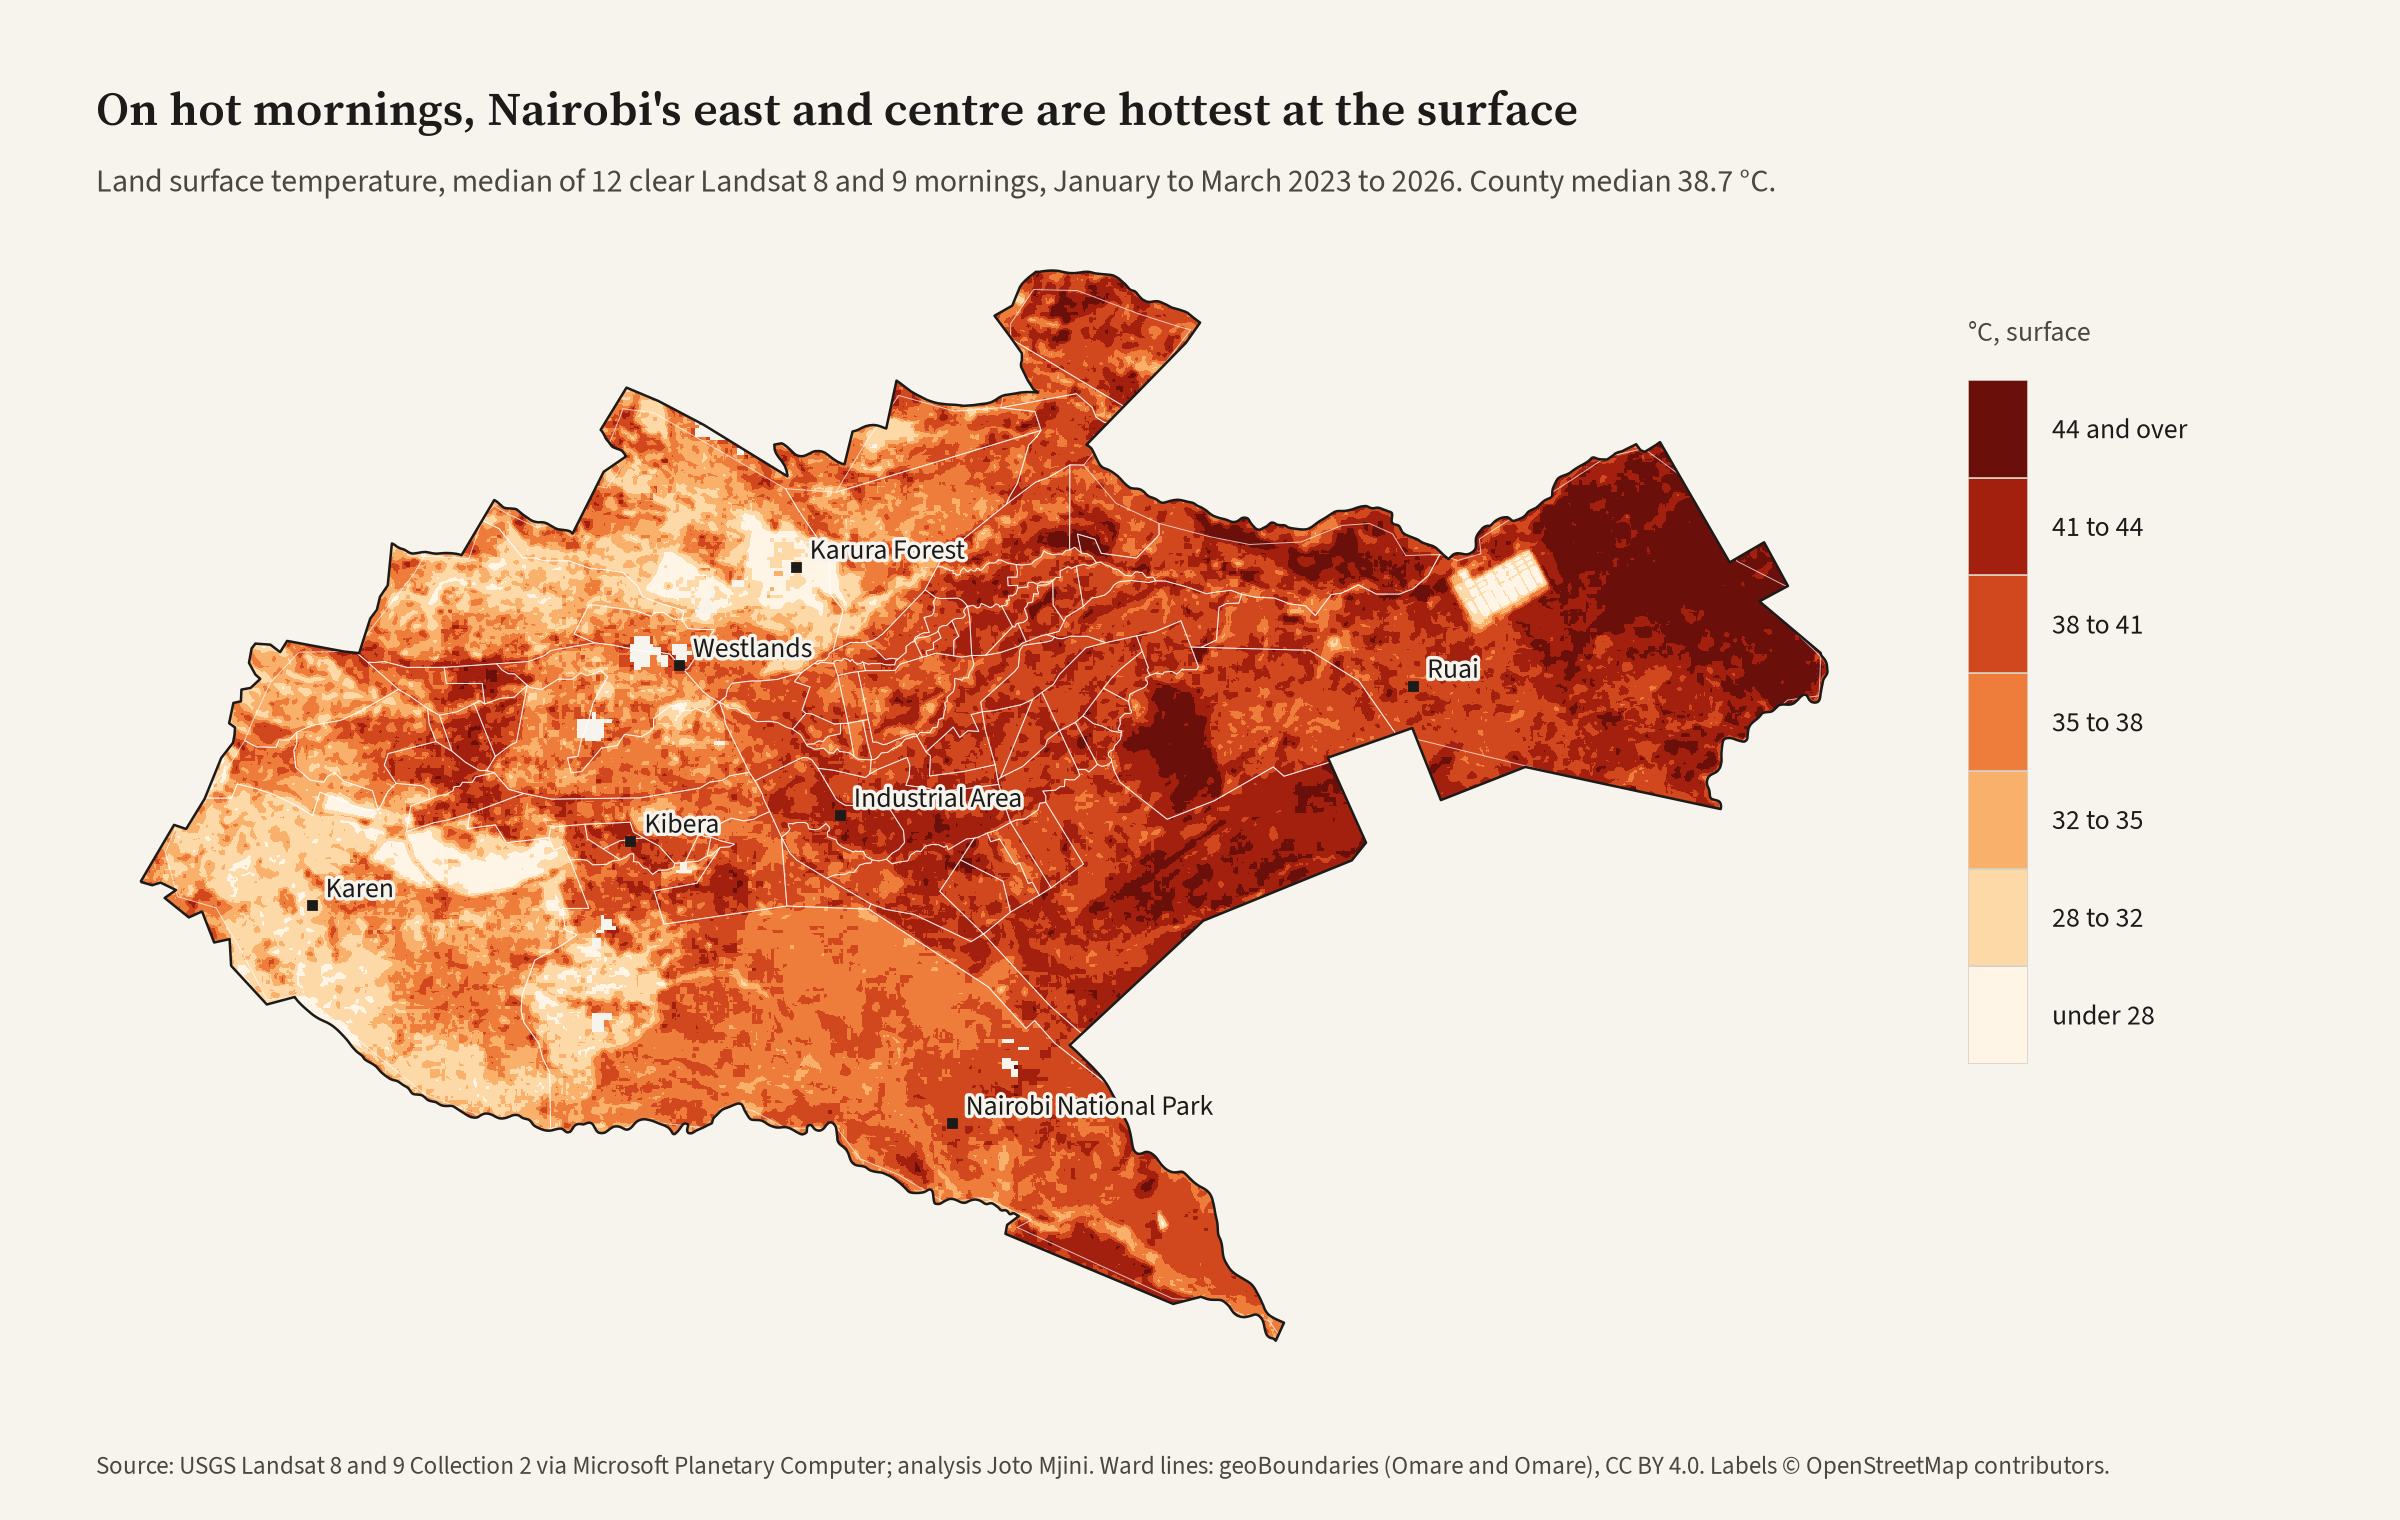

{'county_median_c': 38.7,
 'county_p10_c': 31.6,
 'county_p90_c': 43.3,
 'hottest10pct_land_mean_c': 44.9,
 'coolest10pct_land_mean_c': 29.3,
 'p90_minus_p10_c': 11.7,
 'n_wards_each_group': 8,
 'hottest_wards_mean_c': 41.9,
 'coolest_wards_mean_c': 34.6,
 'ward_gap_c': 7.3,
 'hottest_ward': 'Embakasi',
 'hottest_ward_c': 42.8,
 'coolest_ward': 'Karen',
 'coolest_ward_c': 32.2,
 'cool_season_county_median_c': 34.9,
 'valid_cells_share': 99.6,
 'hot_cool_spearman': 0.9,
 'hot_cool_ward_spearman': 0.75}

In [2]:
display(Image("outputs/figures/hero_map_hot_season.png", width=900))
{k: v for k, v in res["q1"].items() if not isinstance(v, list)}

In [3]:
pd.read_csv("analysis/tables/ward_stats.csv")[["ward_name", "lst_median_c", "lst_anomaly_c", "pop_total", "tree_pct", "rank_hottest"]].head(10)

,ward_name,lst_median_c,lst_anomaly_c,pop_total,tree_pct,rank_hottest
0,Embakasi,42.8,4.1,172204.8,1.1,1
1,Ruai,42.3,3.6,616426.1,3.0,2
2,Kangemi,42.1,3.4,11503.5,11.2,3
3,Mwiki,42.0,3.3,90508.0,3.9,4
4,Viwandani,41.9,3.2,57070.3,2.2,5
5,Kabiro,41.6,3.0,40245.6,5.7,6
6,Baba Dogo,41.4,2.7,40912.1,8.1,7
7,Dandora Area II,41.3,2.6,30297.3,9.2,8
8,Kariobangi North,41.2,2.5,32827.9,4.6,9
9,Kiamaiko,41.2,2.5,54588.4,2.3,10


## 2. How big is the gap between the hottest and coolest places?

In [4]:
res["q2"]

{'CBD': {'median_c': 39.1,
  'mean_c': 39.0,
  'n_cells': 3490,
  'area_km2': 3.15,
  'cool_season_median_c': 36.9},
 'Industrial Area': {'median_c': 41.5,
  'mean_c': 41.5,
  'n_cells': 4788,
  'area_km2': 4.3},
 'Karura Forest': {'median_c': 27.5,
  'mean_c': 28.2,
  'n_cells': 7310,
  'area_km2': 6.66,
  'cool_season_median_c': 24.8},
 'Nairobi Arboretum': {'median_c': 28.8,
  'mean_c': 29.1,
  'n_cells': 369,
  'area_km2': 0.33},
 'hot_areas_median_c': 40.7,
 'cool_areas_median_c': 27.6,
 'gap_c': 13.1,
 'industrial_minus_karura_c': 14.0,
 'cbd_minus_arboretum_c': 10.3,
 'definitions': {'CBD': 'the Nairobi Central ward polygon (IEBC-based ward layer)',
  'industrial': "10 touching OpenStreetMap landuse=industrial polygons merged into one area (the group at the OSM place 'Industrial Area'; ids in analysis/tables/industrial_area_osm_ids.csv)",
  'karura': "OSM polygon 'Karura Forest' (landuse=forest)",
  'arboretum': "OSM polygon 'Nairobi Arboretum' (landuse=forest)"}}

## 3. What do the hottest places have in common?

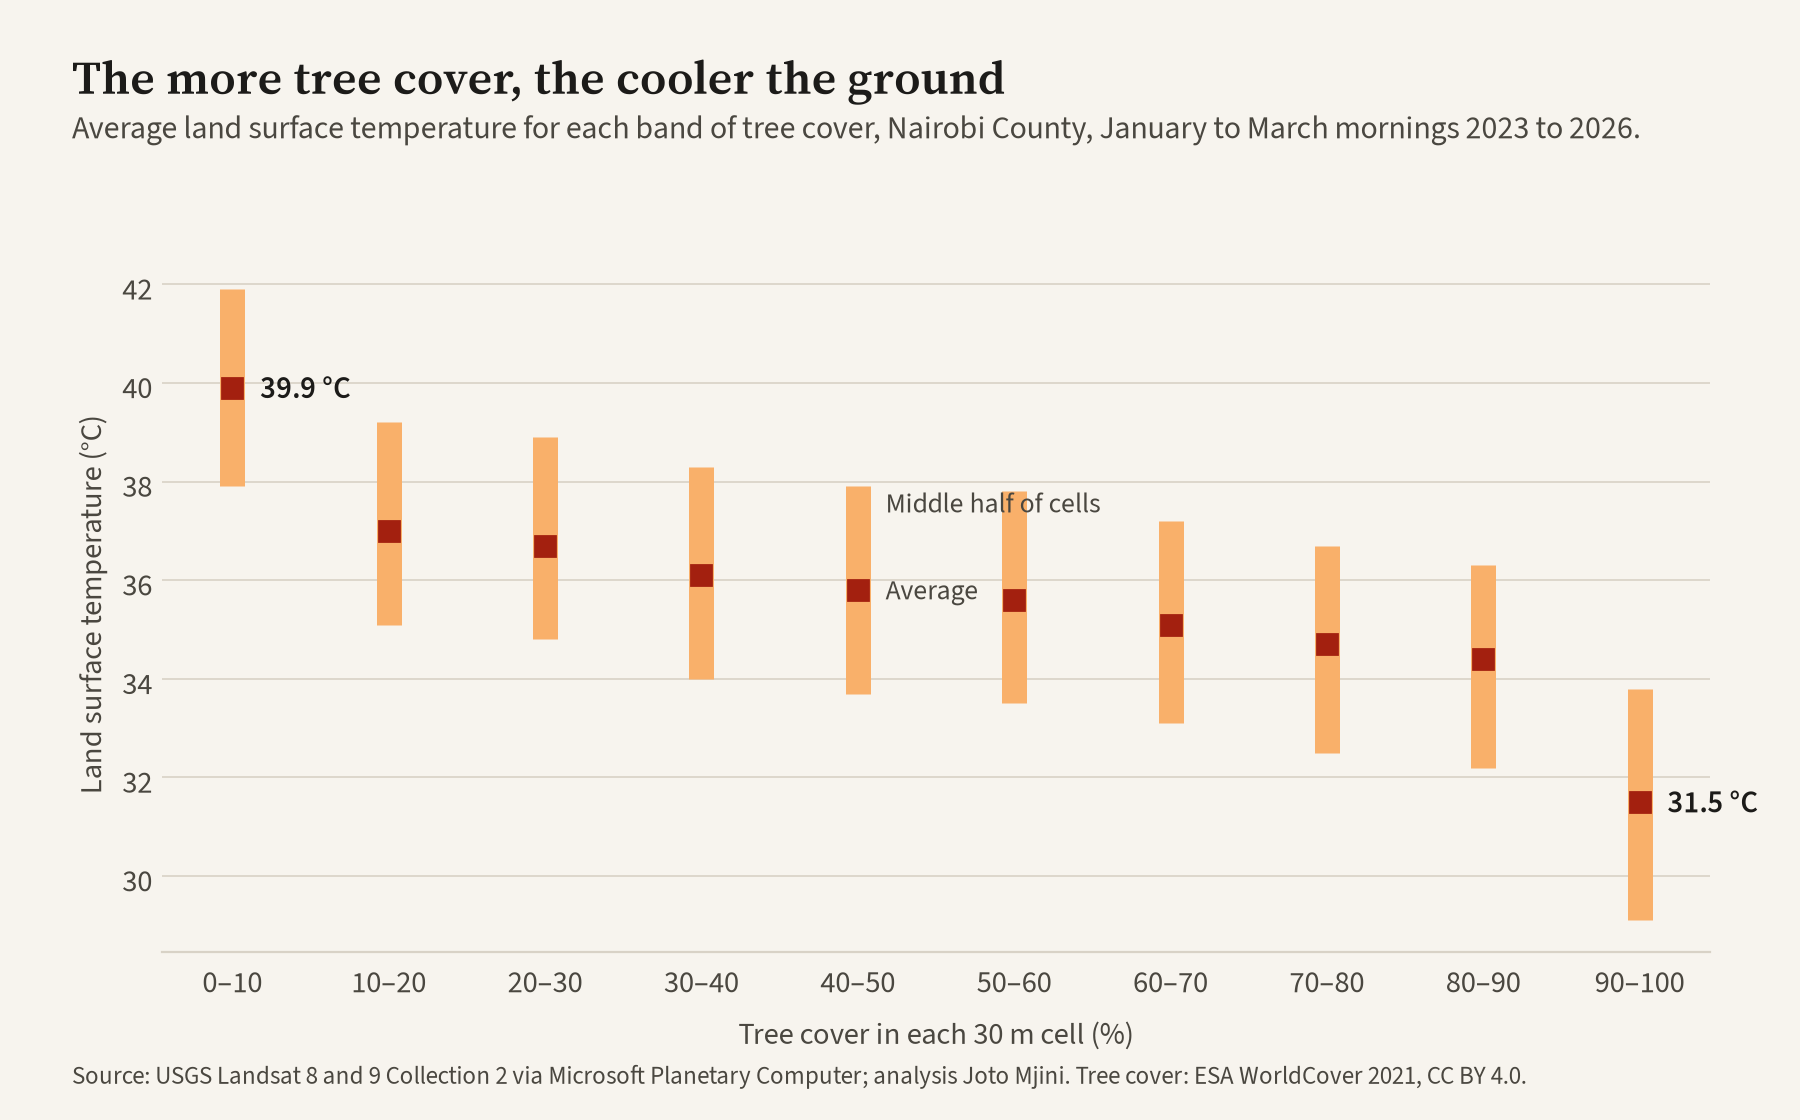

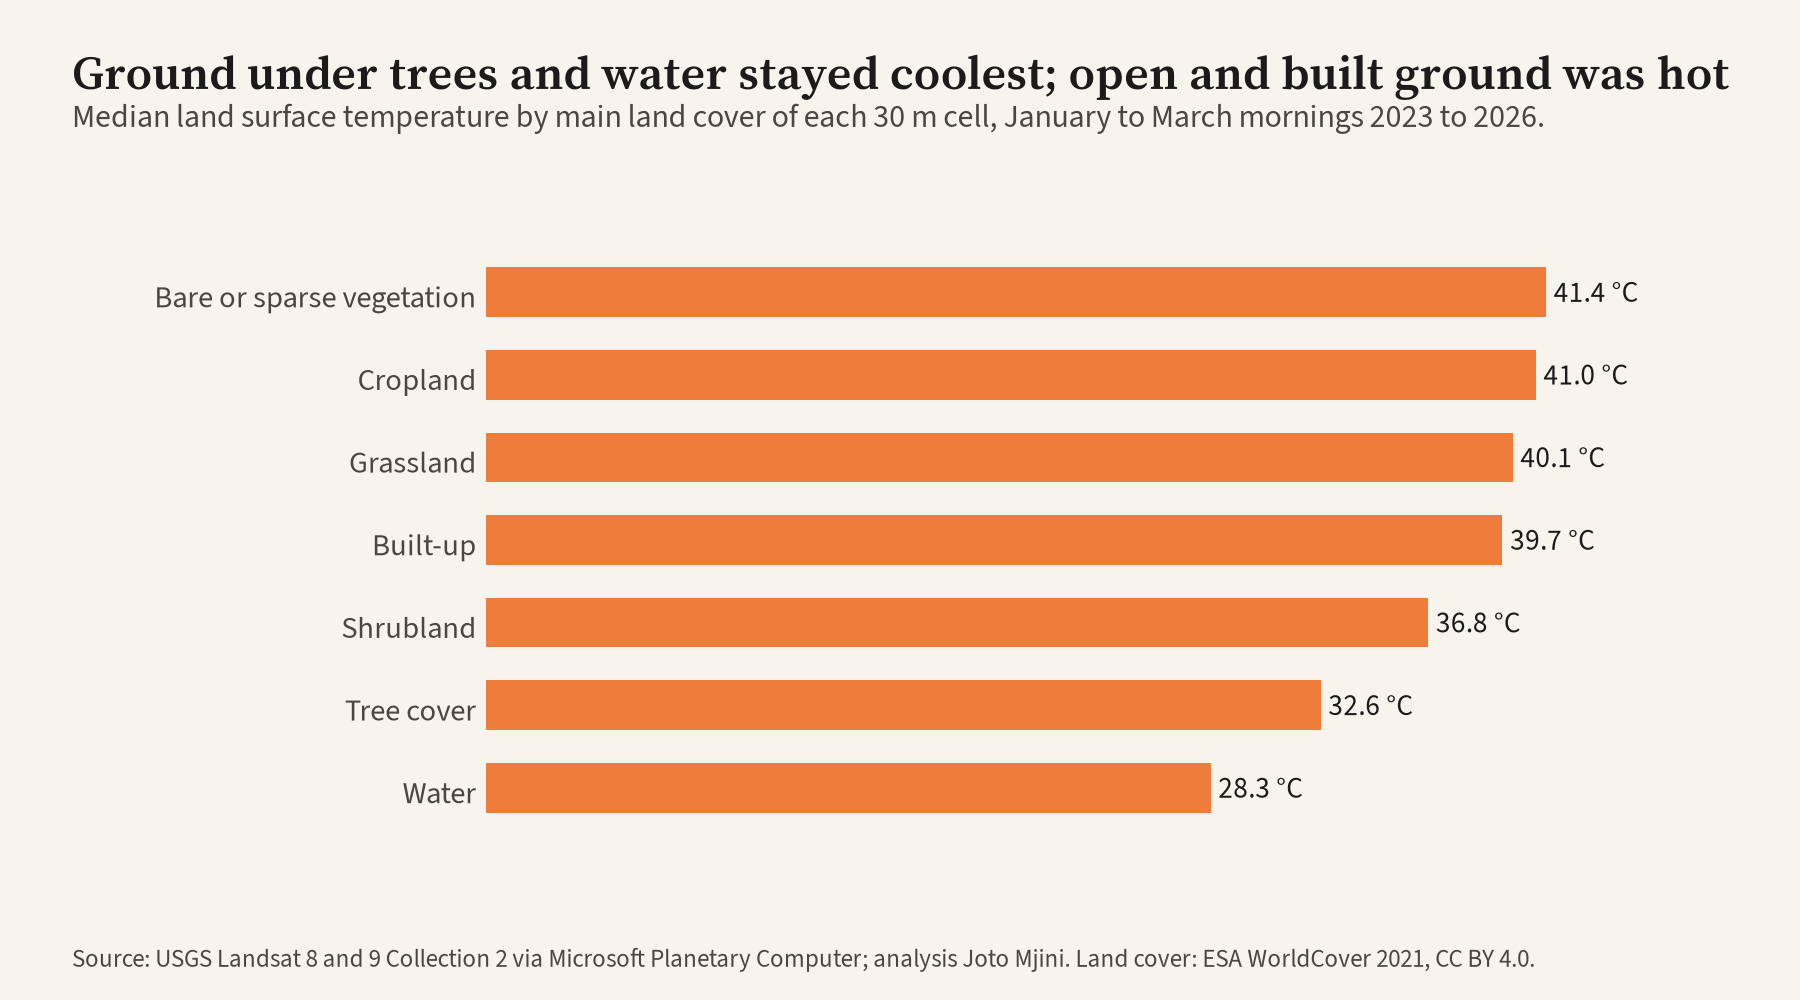

,code,landcover,n_cells,share_pct,median_c,p25_c,p75_c
0,60,Bare or sparse vegetation,8174,1.0,41.4,39.7,43.1
1,40,Cropland,38202,4.9,41.0,39.1,42.9
2,30,Grassland,235778,30.2,40.1,37.9,43.3
3,50,Built-up,247452,31.7,39.7,38.1,41.0
4,20,Shrubland,82182,10.5,36.8,34.7,39.2
5,10,Tree cover,163907,21.0,32.6,30.0,35.3
6,80,Water,4813,0.6,28.3,26.5,31.1


In [5]:
display(Image("outputs/figures/chart_tree_cover_bands.png", width=750))
display(Image("outputs/figures/chart_landcover.png", width=750))
pd.read_csv("analysis/tables/lst_by_landcover.csv")

## 4. Who lives in the hottest places?

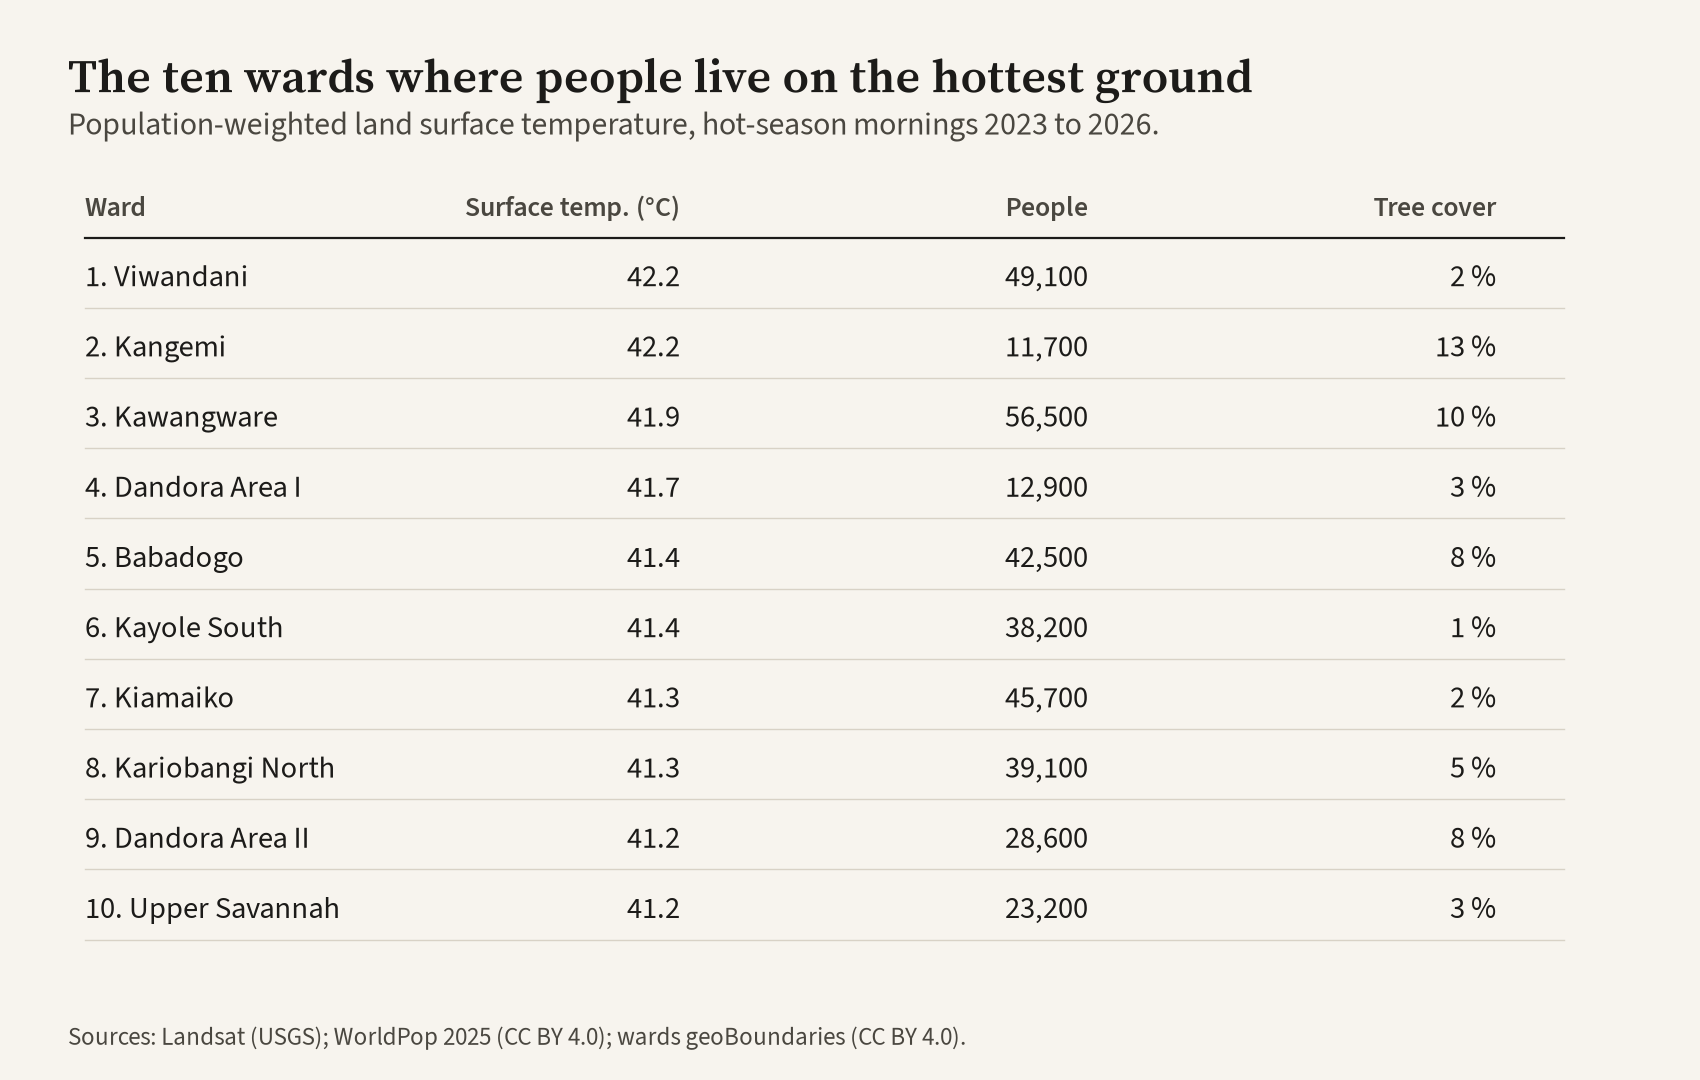

{'hottest20_threshold_c': 41.6,
 'pop_in_hottest20': 827000,
 'pop_in_hottest20_exact': 827100.625,
 'pop_share_in_hottest20_pct': 14.6,
 'county_pop': 5657304,
 'land_share_pct': 20.0,
 'pop_weighted_county_lst_c': 39.4,
 'area_weighted_county_mean_c': 38.1,
 'top10_total_pop': 412000,
 'top10_max_tree_pct': 14.1}

In [6]:
display(Image("outputs/figures/table_top_wards.png", width=700))
{k: v for k, v in res["q4"].items() if k != "top10_pop_weighted"}

## 5. How does a park cool its neighbours?

Built-up cells only, in 100 m rings outside the park edge. The signal is small and noisy; see F9 in FINDINGS for how far to trust it.

In [7]:
pd.read_csv("analysis/tables/park_rings.csv").pivot(index="ring_to_m", columns="park", values="median_c")

park,City Park,Karura Forest,Nairobi Arboretum
ring_to_m,,,
100,37.4,35.5,35.7
200,37.9,36.9,36.4
300,38.2,37.0,36.9
400,38.1,36.8,36.9
500,38.2,37.4,35.8
600,38.3,38.1,36.2
700,38.0,37.6,36.2
800,38.3,37.6,36.4
900,38.4,37.6,36.8


## 6. Is it getting hotter as the city grows?

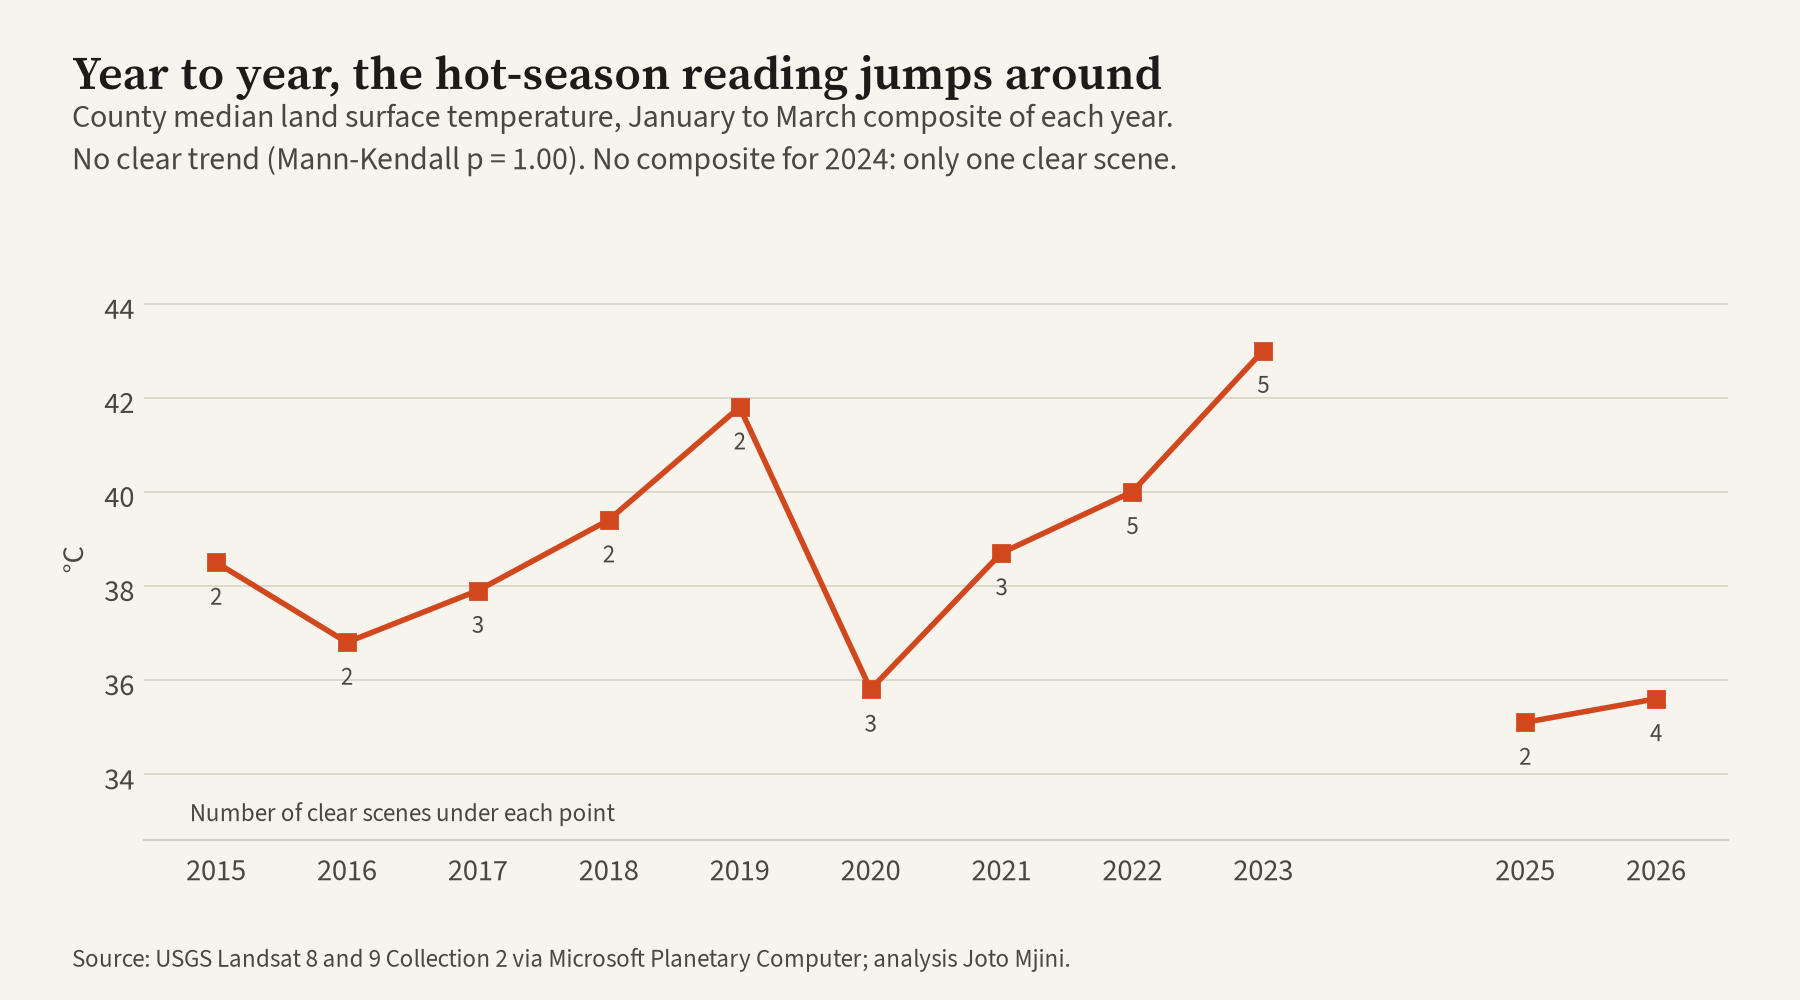

Mann-Kendall: no trend p = 1.0


,epoch,built_km2,projection
0,1975,48.1,False
1,1990,65.8,False
2,2000,82.2,False
3,2010,91.1,False
4,2020,100.8,False
5,2025,103.0,True


In [8]:
display(Image("outputs/figures/chart_hot_season_by_year.png", width=750))
print("Mann-Kendall:", res["q6"]["mann_kendall_trend"], "p =", res["q6"]["mann_kendall_p"])
pd.read_csv("analysis/tables/ghsl_built_by_epoch.csv")

## 7. How unequal is the heat?

In [9]:
q7 = res["q7"]
pd.DataFrame({k: {kk: vv for kk, vv in q7[k].items() if kk != "wards"} for k in ("hottest_fifth", "coolest_fifth")})

,hottest_fifth,coolest_fifth
n_wards,17.0,1.7e+01
pop,655000.0,1.3e+06
pop_weighted_lst_c,41.4,3.7e+01
tree_pct,5.0,3.6e+01
built_pct,84.1,1.8e+01
pop_density_per_km2,21200.0,3.8e+03


## 8. Hot one day, cool the next (air temperature)

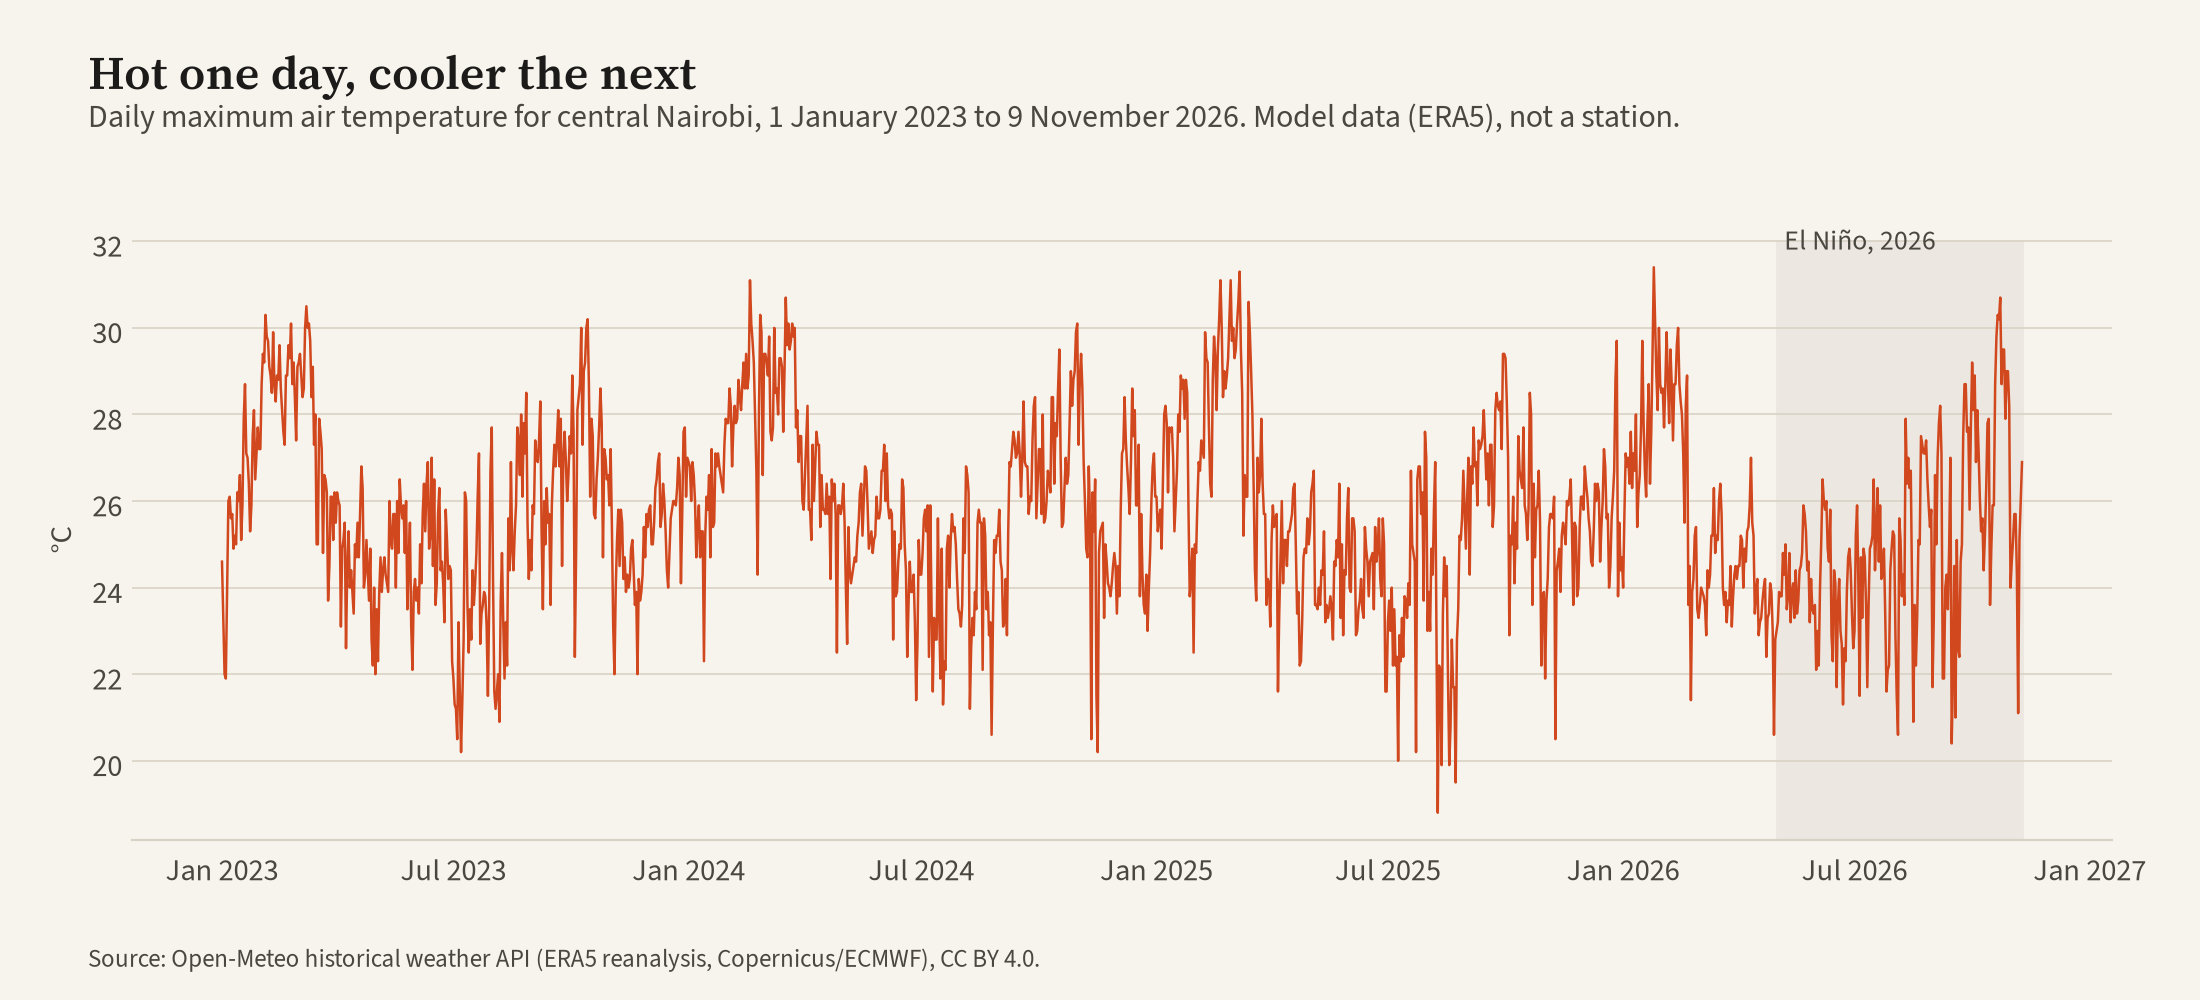

{'p90_tmax_1991_2020_c': 27.2,
 'mean_abs_daily_change_tmax_c': 1.1,
 'days_change_3c_or_more': 68,
 'share_days_change_3c_or_more_pct': 4.8,
 'max_daily_change_c': 6.6,
 'el_nino_period': '2026-05-01 to 2026-11-09',
 'el_nino_mean_tmax_c': 25.0,
 'same_months_1991_2020_mean_tmax_c': 23.2,
 'el_nino_minus_clim_c': 1.7,
 'tmax_2023_now_max_c': 31.4,
 'tmax_2023_now_max_date': '2026-01-25',
 'last_date': '2026-11-09'}

In [10]:
display(Image("outputs/figures/chart_daily_air_temp.png", width=900))
{k: v for k, v in res["q8"].items() if k != "days_above_p90_by_year"}

## Independent checks

In [11]:
chk = checks.main()
{k: (v.get("match") if isinstance(v, dict) and "match" in v else v) for k, v in chk.items()}

2026-11-10 13:56:31 INFO Checks: {"county_median": {"core": 38.7, "independent": 38.7, "method": "rioxarray clip of the composite vs rasterio rasterize mask", "match": true}, "hottest_ward": {"ward": "Embakasi", "core": 42.8, "independent": 42.8, "method": "exactextract coverage-weighted median vs cell-centre median", "match": true}, "coolest_ward": {"ward": "Karen", "core": 32.2, "independent": 32.2, "method": "exactextract coverage-weighted median vs cell-centre median", "match": true}, "ward_rank_agreement_spearman": 1.0, "karura_median": {"core": 27.5, "independent": 27.5, "method": "windowed numpy read with geometry_mask vs full-grid mask", "match": true}, "pop_hottest20": {"core": 827000, "independent": 827000, "method": "xarray clip and threshold vs numpy mask", "match": true}, "spot_cool_places": {"values": {"Karura Forest": 27.5, "Nairobi Arboretum": 28.8, "Nairobi National Park": 37.8, "Nairobi Dam": 34.1, "City Park": 31.4}, "cbd": 39.1, "industrial": 41.5, "all_cooler": tru

{'county_median': True,
 'hottest_ward': True,
 'coolest_ward': True,
 'ward_rank_agreement_spearman': 1.0,
 'karura_median': True,
 'pop_hottest20': True,
 'spot_cool_places': {'values': {'Karura Forest': 27.5,
   'Nairobi Arboretum': 28.8,
   'Nairobi National Park': 37.8,
   'Nairobi Dam': 34.1,
   'City Park': 31.4},
  'cbd': 39.1,
  'industrial': 41.5,
  'all_cooler': True},
 'ward_pop_sum': {'ward_sum': 5588514,
  'county': 5657304,
  'diff_pct': -1.22,
  'within_5pct': True,
  'worldpop_year': 2025},
 'ward_boundaries': {'n_wards': 85,
  'n_wards_ok': True,
  'n_subcounties': 17,
  'subcounties_match_iebc': True,
  'names_not_in_iebc_election_layer': ['Ngei'],
  'median_area_overlap_with_iebc_election_layer_pct': 33.6,
  'min_area_overlap_with_iebc_election_layer_pct': 0.0,
  'county_area_km2': 705.3,
  'ward_union_area_km2': 695.1,
  'symmetric_difference_pct_of_county': 4.59,
  'union_matches_county_ok': True,
  'kibra_wards': {'Laini Saba': {'area_km2': 0.371,
    'pop_worldp

## Write FINDINGS.md

In [12]:
findings.main()
print(Path("analysis/FINDINGS.md").read_text()[:1500])

Wrote /Users/stephanengugi/Desktop/joto-mjini/analysis/FINDINGS.md
# Findings

Every number that may appear in the story, with where it came from. Generated 2026-11-10 13:56 (Africa/Nairobi) by `src/analysis/findings.py` from `analysis/results.json` (written by `src/analysis/core.py`). Do not edit numbers by hand; change the code and re-run.

**Hot-season composite:** median of 12 clear Landsat 8 and 9 scenes, January to March, 2023 to 2026 (2023-01-19, 2023-02-04, 2023-02-12, 2023-02-20, 2023-03-08, 2024-02-15, 2025-01-08, 2025-02-09, 2026-01-03, 2026-01-11, 2026-01-27, 2026-02-12). **Cool-season composite:** 4 scenes, June to August, 2018 to 2026 (2018-08-25, 2020-08-30, 2024-06-14, 2026-07-14). All temperatures below are land surface temperature unless the finding says air temperature.

### F1. On hot mornings, half of Nairobi's ground was hotter than 38.7 °C

- **Sentence for the story:** On clear January to March mornings, half of Nairobi County's ground was hotter than 38.7 °C at